# Parte 4 – Mapas de características

Para segmentar la lesión (Parte 5) hay que decidir **sobre qué** segmentar. La forma más simple sería la imagen misma (la intensidad), pero en la Parte 0 vimos que los histogramas de la lesión y del tejido se superponen bastante. La hipótesis del anteproyecto es que la lesión se distingue del tejido **no solo por su brillo sino también por su textura local**, y que existen mapas que hacen esa diferencia más evidente que la imagen original.

Un **mapa de características** es una imagen nueva, del mismo tamaño que la original, en la que cada píxel vale una medida calculada en una **ventana** alrededor de ese píxel (la media, la varianza, una propiedad de la GLCM...). En vez de elegir el método de segmentación a ciegas, calculamos muchos mapas y **medimos con las máscaras del radiólogo cuál separa mejor la lesión del tejido que la rodea**.

**Qué viene de las partes anteriores:**
- Parte 1: trabajamos sobre las imágenes **sin marcas del ecógrafo**.
- Parte 2: el *speckle* forma **granos de varios píxeles**, así que las ventanas tienen que ser varias veces más grandes que un grano. Y el desvío local depende del brillo, así que la varianza y el coeficiente de variación pueden separar la lesión (oscura) solo por su brillo.
- Parte 3: filtrar mejora los bordes pero **borra la diferencia de textura** entre lesión y tejido. Recomendó calcular los mapas de **textura sobre la imagen sin filtrar** y los de **intensidad y bordes sobre la mediana 7 × 7**. Acá lo **verificamos**: calculamos todos los mapas sobre las dos entradas.

**Contenido**
1. Los mapas y cómo se calculan
2. Los mapas en un ejemplo
3. Cómo medimos la separabilidad: AUC y razón de Fisher
4. Medición en las 647 imágenes con lesión
5. Resultados: ranking de mapas, tamaño de ventana, entrada, clases y redundancia
6. Conclusiones y mapas elegidos para la Parte 5

### Preparación

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, wilcoxon, spearmanr

from busi.datos import listar_casos, cargar_caso
from busi.config import load_config
from busi import artefactos, dominios, mapas

cfg = load_config()
SEED = cfg["SEED"]

def cargar_limpio(caso):
    # Imagen sin marcas del ecógrafo (Parte 1), máscara de la lesión y máscara de las marcas reconstruidas.
    img, mascara = cargar_caso(caso)
    img, marcas = artefactos.limpiar(img)
    return img, mascara, marcas

casos = listar_casos().set_index("id")
con_lesion = casos[casos["clase"] != "normal"]
print(f"{len(con_lesion)} imágenes con lesión: {(con_lesion['clase'] == 'benign').sum()} benignas, "
      f"{(con_lesion['clase'] == 'malignant').sum()} malignas")

NOMBRES = {"intensidad": "Intensidad", "media": "Media local", "varianza": "Varianza local",
           "cv": "Coef. de variación", "gradiente": "Gradiente", "contraste": "GLCM contraste",
           "homogeneidad": "GLCM homogeneidad", "energia": "GLCM energía",
           "correlacion": "GLCM correlación", "entropia": "GLCM entropía"}
ENTRADAS = {"sin_filtrar": "sin filtrar", "mediana_7x7": "mediana 7×7"}

647 imágenes con lesión: 437 benignas, 210 malignas


## 1. Los mapas y cómo se calculan

Para cada píxel tomamos una **ventana** de V × V píxeles centrada en él y calculamos:

| Mapa | Qué mide en la ventana | Fórmula |
|---|---|---|
| **Intensidad** | El nivel de gris del píxel (no usa ventana): la referencia | $g$ |
| **Media local** | El brillo promedio | $\mu = \overline{g}$ |
| **Varianza local** | Cuánto varía el brillo | $\sigma^2 = \overline{g^2} - \overline{g}^{\,2}$ |
| **Coeficiente de variación** | La variación **relativa** al brillo | $\sigma / \mu$ |
| **Gradiente** | Cuántos bordes hay (magnitud de Sobel promediada) | $\overline{\lvert\nabla g\rvert}$ |
| **GLCM contraste** | Diferencia típica entre vecinos | $\sum P(i,j)(i-j)^2$ |
| **GLCM homogeneidad** | Qué tan parecidos son los vecinos | $\sum P(i,j) / (1 + (i-j)^2)$ |
| **GLCM energía** | Qué tan repetidos son los pares (textura uniforme) | $\sqrt{\sum P(i,j)^2}$ |
| **GLCM correlación** | Qué tan predecible es un píxel a partir de su vecino | $\sum P(i,j)\,(i-\mu)(j-\mu) / \sigma^2$ |
| **GLCM entropía** | Qué tan desordenada es la textura | $-\sum P(i,j)\log_2 P(i,j)$ |

La media y la varianza se calculan con el **filtro promediador** (`uniform_filter`) sobre $g$ y $g^2$, como en la Parte 2.

**La GLCM local** usa la imagen cuantizada a 16 niveles (`mapas.reducir_niveles`), distancia 1 y la matriz **sumada en las 4 direcciones** (0°, 45°, 90°, 135°) y en los dos sentidos (simétrica), así el mapa no depende de la orientación de la textura.

Calcular una GLCM con `graycomatrix` en cada uno de los ~100 000 píxeles de un recorte sería lentísimo. Pero **cada propiedad es un promedio sobre los pares de píxeles vecinos de la ventana**: el contraste es el promedio de $(i-j)^2$, cada casilla $P(i,j)$ es la fracción de pares que valen $(i, j)$, etc. Y un promedio sobre una ventana deslizante es justamente un **filtro de media**. `mapas.mapas_glcm()` arma, para cada dirección, una imagen con el valor de cada par y le aplica el filtro de media, cuidando que **los dos píxeles del par** caigan dentro de la ventana. Es exacto: lo comprobamos contra `graycomatrix` en píxeles al azar.

In [3]:
EJEMPLO = "benign (436)"
img, mascara, marcas = cargar_limpio(casos.loc[EJEMPLO])
zona = dominios.recorte(mascara, margen=40)
q = mapas.reducir_niveles(img[zona], 16)

rng = np.random.default_rng(SEED)
for ventana in mapas.VENTANAS:
    mapa = mapas.mapas_glcm(q, ventana)
    h = ventana // 2
    error = 0
    for _ in range(200):
        y, x = rng.integers(0, q.shape[0]), rng.integers(0, q.shape[1])
        ref = mapas.glcm_ventana(q[max(y - h, 0):y + h + 1, max(x - h, 0):x + h + 1])   # skimage, de a una ventana
        error = max(error, max(abs(mapa[k][y, x] - ref[k]) for k in ref))
    print(f"ventana {ventana:2d}: diferencia máxima con graycomatrix en 200 píxeles al azar = {error:.1e}")

ventana  7: diferencia máxima con graycomatrix en 200 píxeles al azar = 9.3e-13


ventana 15: diferencia máxima con graycomatrix en 200 píxeles al azar = 4.3e-13


ventana 31: diferencia máxima con graycomatrix en 200 píxeles al azar = 3.5e-13


**Qué vemos:** en los 600 píxeles probados, los mapas de `mapas_glcm()` coinciden con `graycomatrix` hasta la duodécima cifra decimal (el error es de redondeo). El método rápido calcula **exactamente** lo mismo, pero en todos los píxeles a la vez: unos 150 ms por recorte, contra varios minutos píxel por píxel.

## 2. Los mapas en un ejemplo

Los diez mapas de `benign (436)` con ventana de 15 px, sobre la imagen sin filtrar. En rojo, el borde de la lesión según el radiólogo. Cada mapa tiene su propia escala de colores (de su percentil 1 al 99).

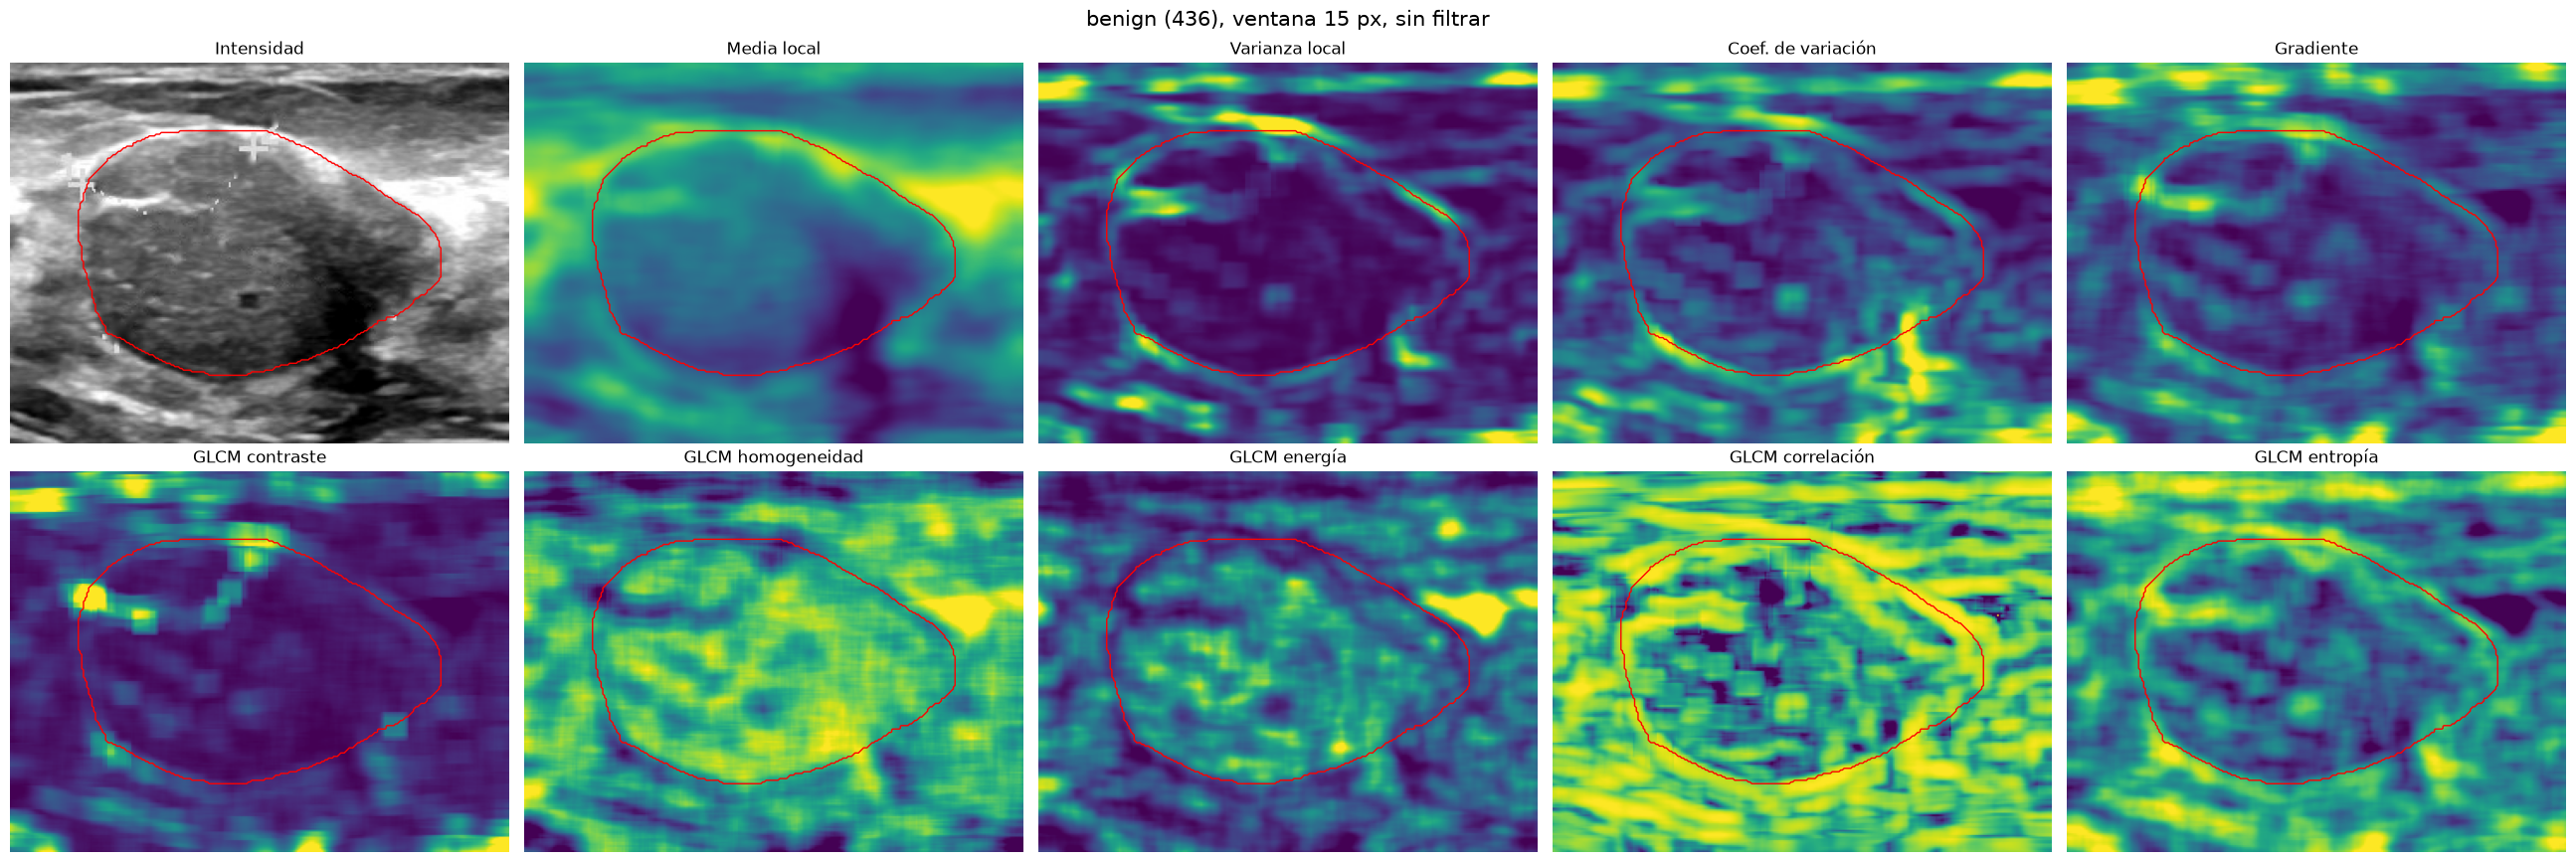

In [4]:
def mostrar_mapas(img, mascara, zona, ventana, titulo):
    todos = mapas.calcular_mapas(img[zona].astype(float), ventana)
    fig, axes = plt.subplots(2, 5, figsize=(26, 9))
    for ax, nombre in zip(axes.flat, mapas.MAPAS):
        m = todos[nombre]
        lim = np.percentile(m, [1, 99])
        ax.imshow(m, cmap="gray" if nombre == "intensidad" else "viridis", vmin=lim[0], vmax=lim[1])
        ax.contour(mascara[zona], levels=[0.5], colors="red", linewidths=1)
        ax.set_title(NOMBRES[nombre])
        ax.axis("off")
    fig.suptitle(titulo, fontsize=15)
    plt.tight_layout()
    plt.show()

mostrar_mapas(img, mascara, zona, 15, f"{EJEMPLO}, ventana 15 px, sin filtrar")

**Qué vemos:**
- **Intensidad y media local:** la lesión es más **oscura** que el tejido de alrededor (hipoecoica, como vimos en la Parte 0). La media local saca el grano y la lesión queda como una mancha oscura. Pero la **sombra** que hay debajo y a la derecha de la lesión también es oscura: la media sola no distingue la lesión de otras zonas oscuras.
- **Varianza, gradiente, contraste y entropía** valen **poco dentro de la lesión** (su interior tiene menos variación) y mucho en las capas brillantes de tejido.
- **Homogeneidad y energía** hacen lo contrario: son **altas dentro de la lesión** (textura más uniforme).
- La **GLCM correlación** marca un **anillo sobre el borde** de la lesión: una ventana que cae sobre el borde tiene píxeles claros de un lado y oscuros del otro, así que cada píxel es muy predecible a partir de su vecino. Marca el **borde**, no la región.
- En algunos mapas aparecen **cuadrados**: la ventana cuadrada deja su forma alrededor de puntos brillantes aislados.

Lo mismo en una lesión **maligna**, que en la Parte 0 vimos que tiene menos contraste con el tejido que la rodea:

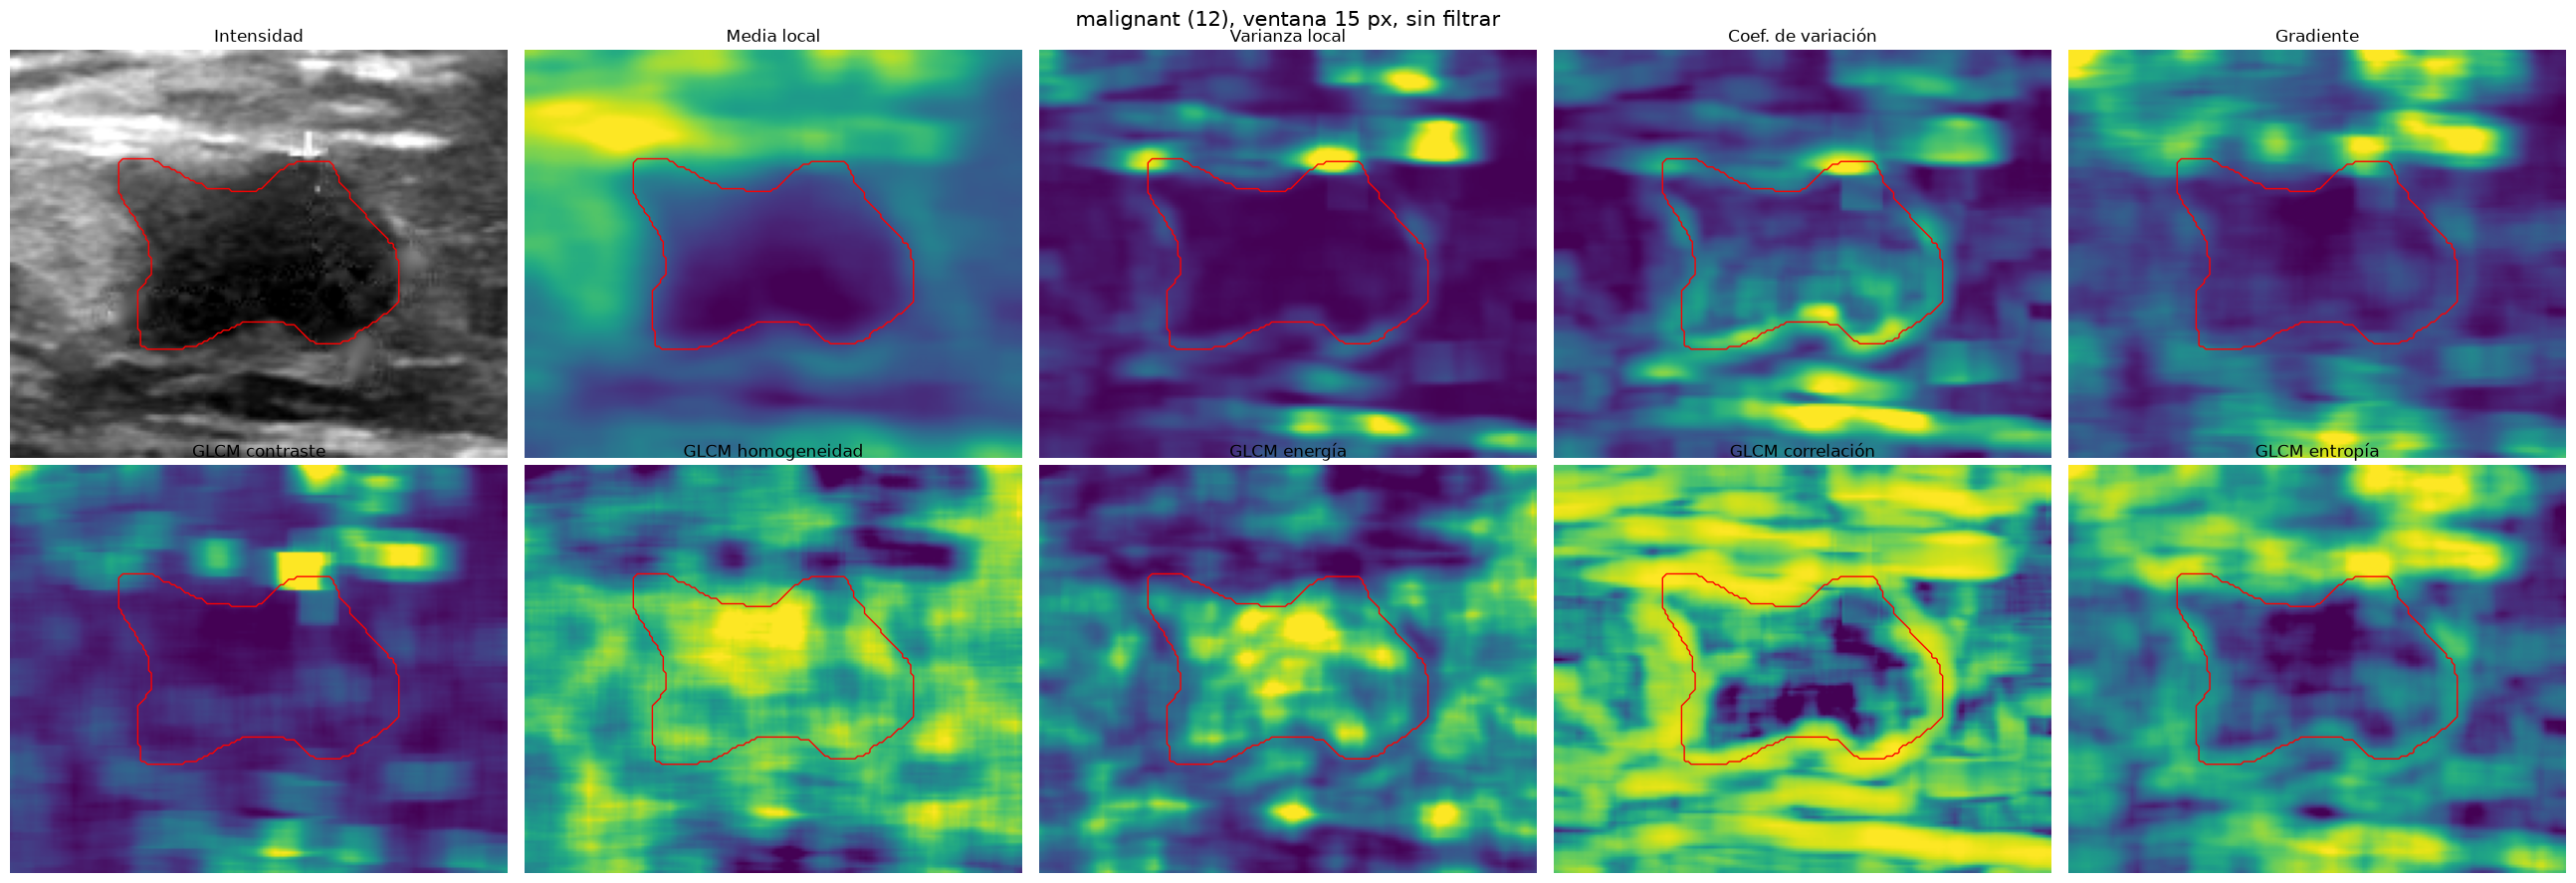

In [5]:
EJEMPLO_M = "malignant (12)"
img_m, mascara_m, marcas_m = cargar_limpio(casos.loc[EJEMPLO_M])
mostrar_mapas(img_m, mascara_m, dominios.recorte(mascara_m, margen=40), 15, f"{EJEMPLO_M}, ventana 15 px, sin filtrar")

**Qué vemos:** esta lesión es muy oscura y homogénea, así que casi todos los mapas la destacan: media, varianza y gradiente bajos adentro; homogeneidad y energía altas. Otra vez la **correlación** dibuja un anillo sobre el borde. Y otra vez el tejido oscuro de abajo se confunde con la lesión en la media local.

### 2.1 El tamaño de la ventana

El mismo mapa (GLCM energía) con las tres ventanas:

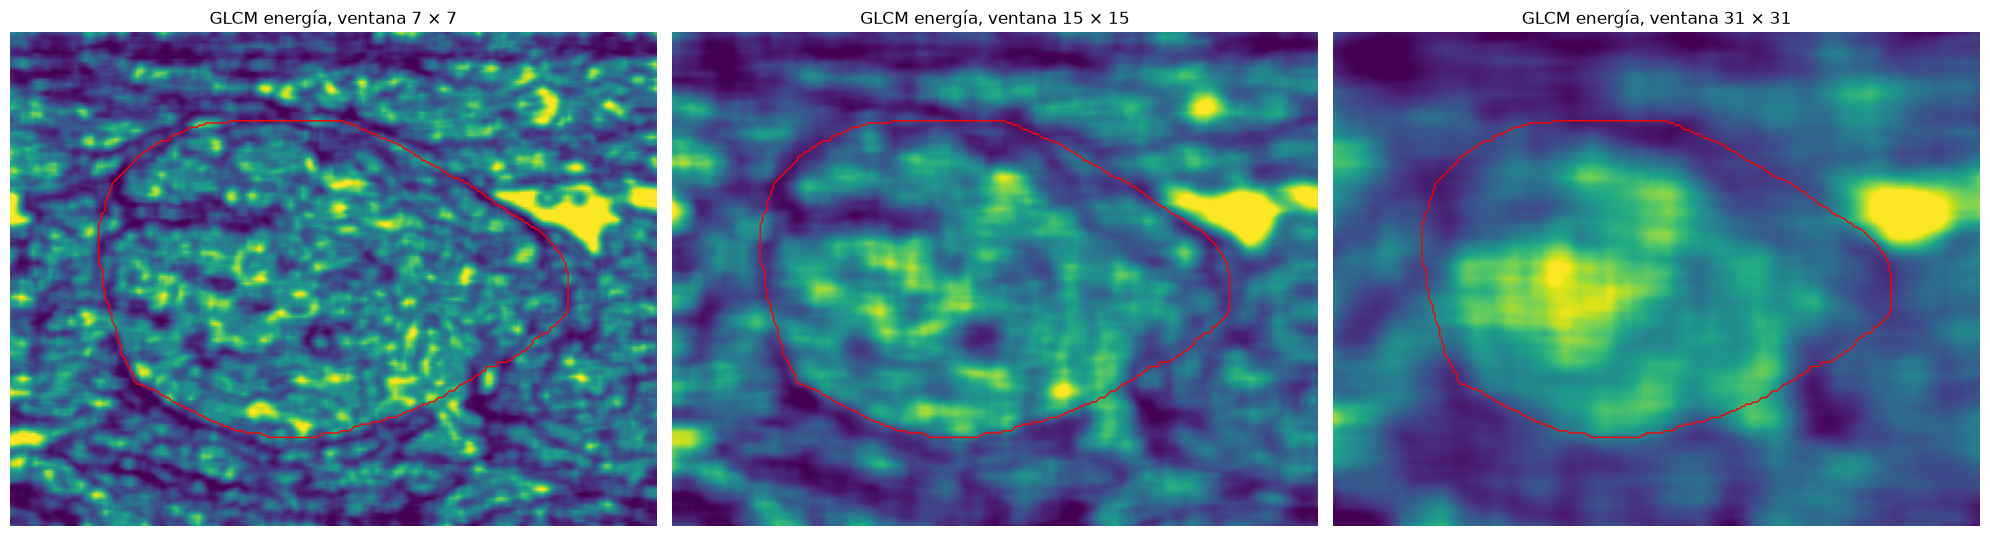

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, ventana in zip(axes, mapas.VENTANAS):
    m = mapas.calcular_mapas(img[zona].astype(float), ventana)["energia"]
    lim = np.percentile(m, [1, 99])
    ax.imshow(m, cmap="viridis", vmin=lim[0], vmax=lim[1])
    ax.contour(mascara[zona], levels=[0.5], colors="red", linewidths=1)
    ax.set_title(f"GLCM energía, ventana {ventana} × {ventana}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:**
- Con **7 × 7** el mapa es muy ruidoso: la ventana abarca pocos granos de *speckle* (la Parte 2 mostró que cada grano mide varios píxeles), así que la GLCM se estima con muy pocos pares independientes.
- Con **31 × 31** el mapa es suave y la zona de energía alta se concentra en la lesión, pero **ya no sigue su borde**: la ventana mezcla lesión y tejido en una franja ancha alrededor del contorno.
- Es el compromiso de cualquier mapa con ventana: **ventana grande = estimación más estable, borde más borroso**.

## 3. Cómo medimos la separabilidad

Para cada imagen comparamos los valores del mapa en dos regiones (las mismas de la Parte 3):
- **lesión:** el interior de la máscara, sin la banda de 3 px del borde (la máscara manual no es exacta al píxel);
- **tejido:** un anillo entre 5 y 20 px por fuera del borde.

En las dos se excluyen los píxeles de marcas reconstruidas.

Con dos medidas:
- **AUC** (área bajo la curva ROC): la probabilidad de que un píxel de la lesión elegido al azar tenga un valor **mayor** que uno del tejido. 0,5 = el mapa no los separa; 1 = la lesión siempre mayor; 0 = la lesión siempre menor. Un AUC de 0,1 separa **igual de bien** que uno de 0,9, solo que al revés. Por eso resumimos con el **AUC efectivo** = $\max(\text{AUC}, 1 - \text{AUC})$ y aparte miramos el **sentido**.
- **Razón de Fisher**: $F = (\mu_\text{lesión} - \mu_\text{tejido})^2 / (\sigma^2_\text{lesión} + \sigma^2_\text{tejido})$, cuánto se alejan las medias en relación a la dispersión. A diferencia del AUC, depende de la escala del mapa y se deja arrastrar por valores extremos.

**Importante:** el AUC se calcula **dentro de cada imagen** (píxeles de la lesión contra píxeles del tejido de la misma imagen), que es lo que necesita la segmentación: separar la lesión de *su* entorno. Después resumimos las 647 imágenes con la mediana.

En el ejemplo, para la intensidad y el GLCM energía:

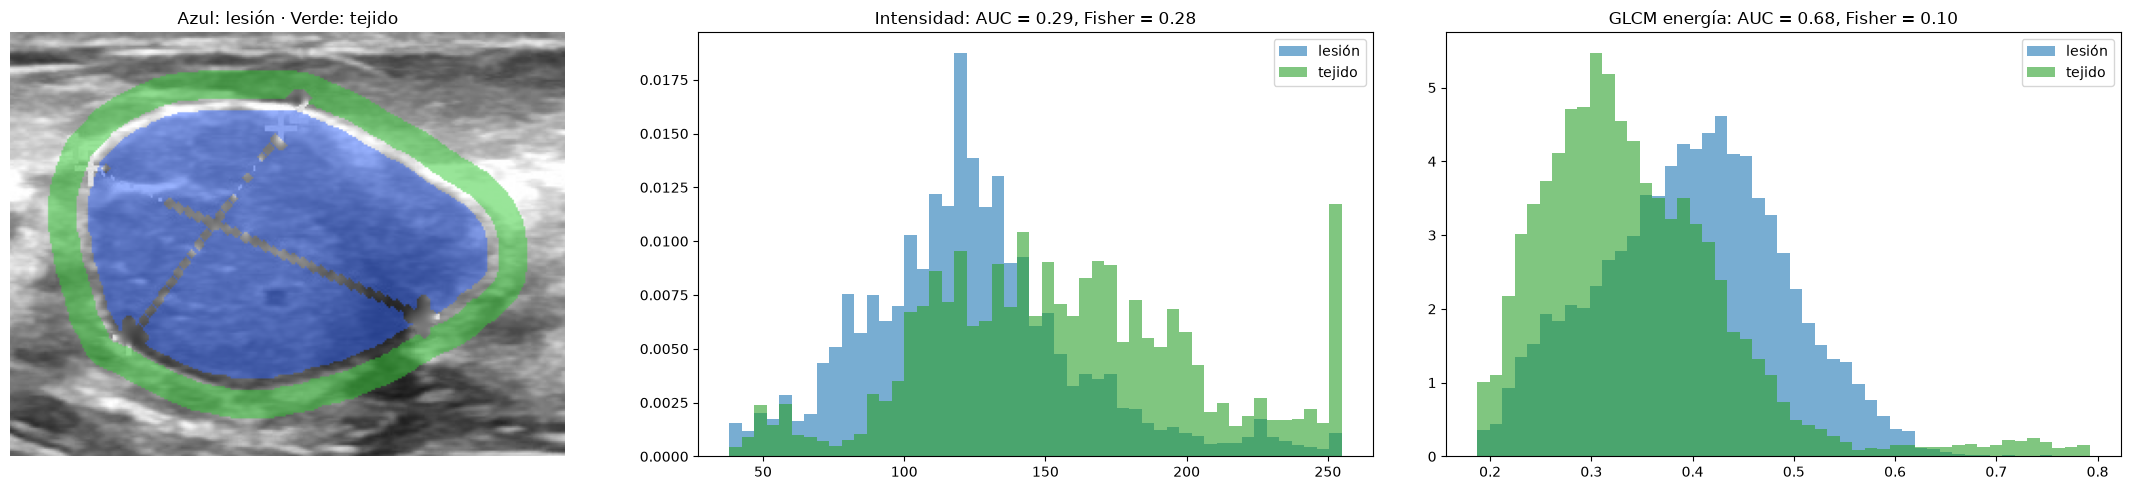

In [7]:
m, mk = mascara[zona], marcas[zona]
lesion = m & ~dominios.contorno(m) & ~mk
tejido = dominios.anillo(m) & ~mk
todos = mapas.calcular_mapas(img[zona].astype(float), 15)

fig, axes = plt.subplots(1, 3, figsize=(22, 5))
rgb = np.dstack([img[zona]] * 3).astype(float) / 255
rgb[lesion] = 0.5 * rgb[lesion] + 0.5 * np.array([0.2, 0.4, 1])
rgb[tejido] = 0.5 * rgb[tejido] + 0.5 * np.array([0.2, 0.8, 0.2])
axes[0].imshow(rgb)
axes[0].set_title("Azul: lesión · Verde: tejido")
axes[0].axis("off")
for ax, nombre in zip(axes[1:], ["intensidad", "energia"]):
    auc, fisher = mapas.separabilidad(todos[nombre], lesion, tejido)
    rango = np.percentile(todos[nombre][lesion | tejido], [0.5, 99.5])
    bins = np.linspace(*rango, 50)
    ax.hist(todos[nombre][lesion], bins=bins, alpha=0.6, density=True, color="tab:blue", label="lesión")
    ax.hist(todos[nombre][tejido], bins=bins, alpha=0.6, density=True, color="tab:green", label="tejido")
    ax.set_title(f"{NOMBRES[nombre]}: AUC = {auc:.2f}, Fisher = {fisher:.2f}")
    ax.legend()
plt.tight_layout()
plt.show()

**Qué vemos:** en esta imagen la intensidad tiene AUC = 0,29: la lesión es **más oscura** que el tejido (AUC efectivo 0,71). La energía tiene AUC = 0,68: la lesión tiene **más** energía. Los dos histogramas se superponen bastante en los dos mapas; ningún umbral separaría perfectamente. En el tejido se ve el pico en 255 de las fibras brillantes.

## 4. Medición en las 647 imágenes con lesión

`mapas.medir_caso()` calcula los 10 mapas sobre las 2 entradas con las 3 ventanas (la intensidad una sola vez por entrada, porque no usa ventana) y mide su separabilidad: 56 combinaciones por imagen. Los mapas se calculan en un recorte alrededor de la lesión, con margen suficiente para la ventana más grande.

Tarda alrededor de **20 minutos**. Los resultados se guardan en `outputs/mapas/` (no se sube a GitHub); si el archivo existe se lee directamente. Mientras calcula guarda un resultado parcial cada 50 imágenes: si se corta, al volver a ejecutar retoma desde donde quedó. Para recalcular todo, poner `RECALCULAR = True`.

In [8]:
RECALCULAR = False
archivo = cfg["OUTPUT_DIR"] / "mapas" / "separabilidad.csv"

parcial = archivo.with_name("separabilidad_parcial.csv")    # se guarda cada 50 imágenes: si se corta, retoma

if archivo.exists() and not RECALCULAR:
    sep = pd.read_csv(archivo)
    print("Resultados leídos de", archivo)
else:
    archivo.parent.mkdir(parents=True, exist_ok=True)
    filas = pd.read_csv(parcial).to_dict("records") if parcial.exists() and not RECALCULAR else []
    hechas = {f["id"] for f in filas}
    if hechas:
        print(f"Retomando: {len(hechas)} imágenes ya calculadas")
    pendientes = con_lesion[~con_lesion.index.isin(hechas)]
    for i, (id_caso, caso) in enumerate(pendientes.iterrows()):
        im, masc, mk = cargar_limpio(caso)
        for fila in mapas.medir_caso(im, masc, mk):
            fila.update(id=id_caso, clase=caso["clase"])
            filas.append(fila)
        if (i + 1) % 50 == 0:
            pd.DataFrame(filas).to_csv(parcial, index=False)
            print(f"{len(hechas) + i + 1} de {len(con_lesion)} imágenes")
    sep = pd.DataFrame(filas)
    sep.to_csv(archivo, index=False)
    parcial.unlink(missing_ok=True)

sep["auc_efectivo"] = np.maximum(sep["auc"], 1 - sep["auc"])
print(f"{sep['id'].nunique()} imágenes, {len(sep)} filas")

Resultados leídos de C:\PSIB\TPI\PSIB_TPI_GRUPO_13\outputs\mapas\separabilidad.csv
647 imágenes, 36232 filas


## 5. Resultados

### 5.1 ¿Qué mapa separa mejor la lesión del tejido?

AUC efectivo **mediano** de las 647 imágenes, para cada mapa, entrada y ventana. La intensidad no usa ventana: aparece igual en las tres columnas de cada entrada.

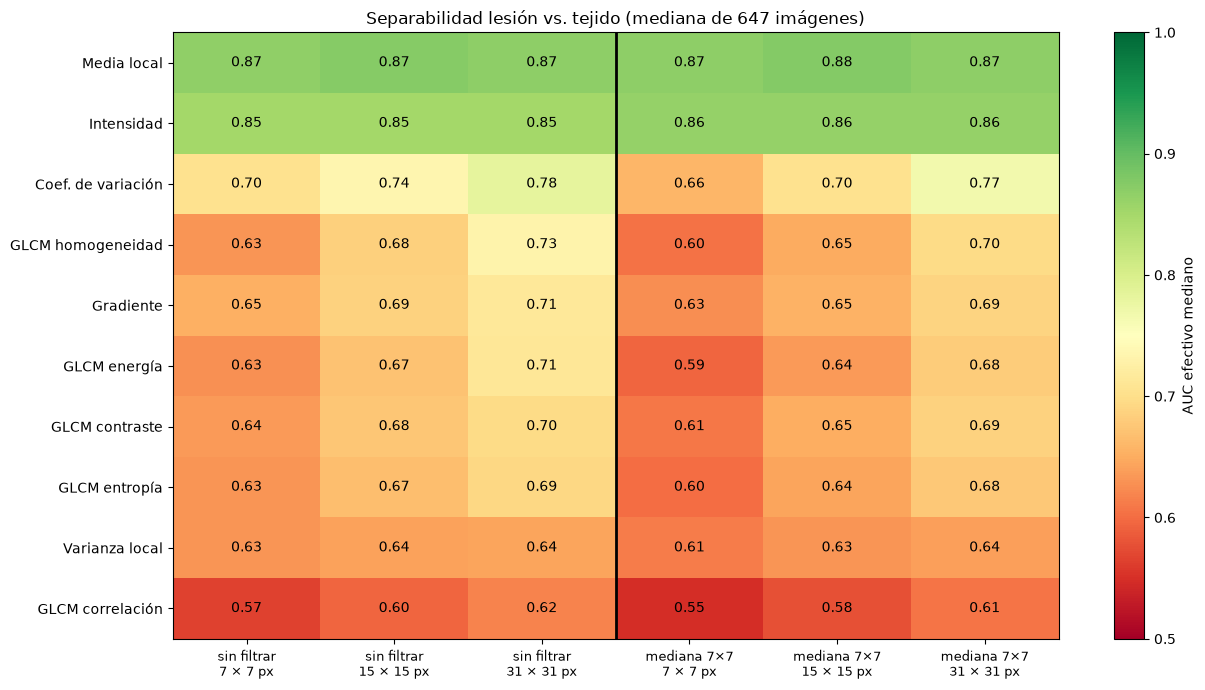

In [9]:
tabla = sep.groupby(["mapa", "entrada", "ventana"])["auc_efectivo"].median().unstack(["entrada", "ventana"])
# la intensidad (ventana 0) se repite en las tres ventanas para poder mostrarla en la misma tabla
for e in ENTRADAS:
    for v in mapas.VENTANAS:
        tabla[(e, v)] = tabla[(e, v)].fillna(tabla[(e, 0)])
tabla = tabla[[(e, v) for e in ENTRADAS for v in mapas.VENTANAS]]
tabla = tabla.loc[tabla.max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(13, 7))
h = ax.imshow(tabla.values, cmap="RdYlGn", vmin=0.5, vmax=1, aspect="auto")
ax.set_xticks(range(tabla.shape[1]))
ax.set_xticklabels([f"{ENTRADAS[e]}\n{v} × {v} px" for e, v in tabla.columns], fontsize=9)
ax.set_yticks(range(tabla.shape[0]))
ax.set_yticklabels([NOMBRES[m] for m in tabla.index])
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        ax.text(j, i, f"{tabla.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
ax.axvline(2.5, color="black", linewidth=2)
plt.colorbar(h, ax=ax, label="AUC efectivo mediano")
ax.set_title("Separabilidad lesión vs. tejido (mediana de 647 imágenes)")
plt.tight_layout()
plt.show()

In [10]:
# sentido: en qué porcentaje de las imágenes la lesión tiene un valor MENOR que el tejido (AUC < 0,5)
resumen = (sep.groupby(["mapa", "entrada", "ventana"])
           .agg(auc_efectivo=("auc_efectivo", "median"),
                fisher=("fisher", "median"),
                lesion_menor=("auc", lambda s: 100 * (s < 0.5).mean()))
           .reset_index())
idx_mejor = resumen.groupby("mapa")["auc_efectivo"].idxmax()
mejores = resumen.loc[idx_mejor].sort_values("auc_efectivo", ascending=False)
mejores["mapa"] = mejores["mapa"].map(NOMBRES)
mejores["entrada"] = mejores["entrada"].map(ENTRADAS)
mejores = mejores.rename(columns={"lesion_menor": "% imágenes con lesión menor"}).set_index("mapa")
print("Mejor combinación de cada mapa:")
mejores.round(3)

Mejor combinación de cada mapa:


,entrada,ventana,auc_efectivo,fisher,% imágenes con lesión menor
mapa,,,,,
Media local,mediana 7×7,15,0.876,1.328,97.372
Intensidad,mediana 7×7,0,0.862,1.145,97.372
Coef. de variación,sin filtrar,31,0.782,0.536,8.810
GLCM homogeneidad,sin filtrar,31,0.731,0.376,10.819
Gradiente,sin filtrar,31,0.714,0.329,86.090
GLCM energía,sin filtrar,31,0.712,0.335,14.529
GLCM contraste,sin filtrar,31,0.697,0.226,83.153
GLCM entropía,sin filtrar,31,0.692,0.274,81.762
Varianza local,sin filtrar,31,0.643,0.082,65.842


**Qué vemos:**
- **El mejor mapa es la media local** (AUC efectivo 0,87–0,88 en todas las combinaciones), seguida por la **intensidad** sola (0,85–0,86). La lesión es más oscura que el tejido en el **97 %** de las imágenes.
- **Los mapas de textura separan menos:** el mejor es el **coeficiente de variación** (0,78), después la homogeneidad (0,73), el gradiente y la energía (0,71), el contraste (0,70) y la entropía (0,69). La varianza (0,64) y la correlación (0,62) separan poco.
- **El sentido es consistente** en casi todos: la lesión tiene **más** coeficiente de variación, homogeneidad y energía (en el 85–91 % de las imágenes) y **menos** gradiente, contraste y entropía (82–86 %). Las excepciones son la **varianza** (66 %) y la **correlación**, que en el 45 % de las imágenes va para un lado y en el 55 % para el otro.
- La **razón de Fisher** ordena los mapas de forma parecida. Es especialmente baja para la varianza (0,08), que tiene valores extremos en las fibras brillantes.

**La hipótesis del anteproyecto se cumple solo en parte.** Esperábamos que algún mapa de textura separara la lesión mejor que la imagen original, y **no pasa**: el brillo (la hipoecogenicidad de la lesión) es la diferencia principal. La media local mejora un poco respecto de la intensidad sola porque promedia el *speckle*. La textura separa menos, pero puede aportar **información distinta** (sección 5.5).

**Ojo con el coeficiente de variación:** en la Parte 2 vimos que el desvío del *speckle* crece con el brillo en el tejido oscuro, así que σ/μ es alto donde la imagen es oscura. Parte de lo que separa es, otra vez, que la lesión es oscura.

### 5.2 El tamaño de la ventana

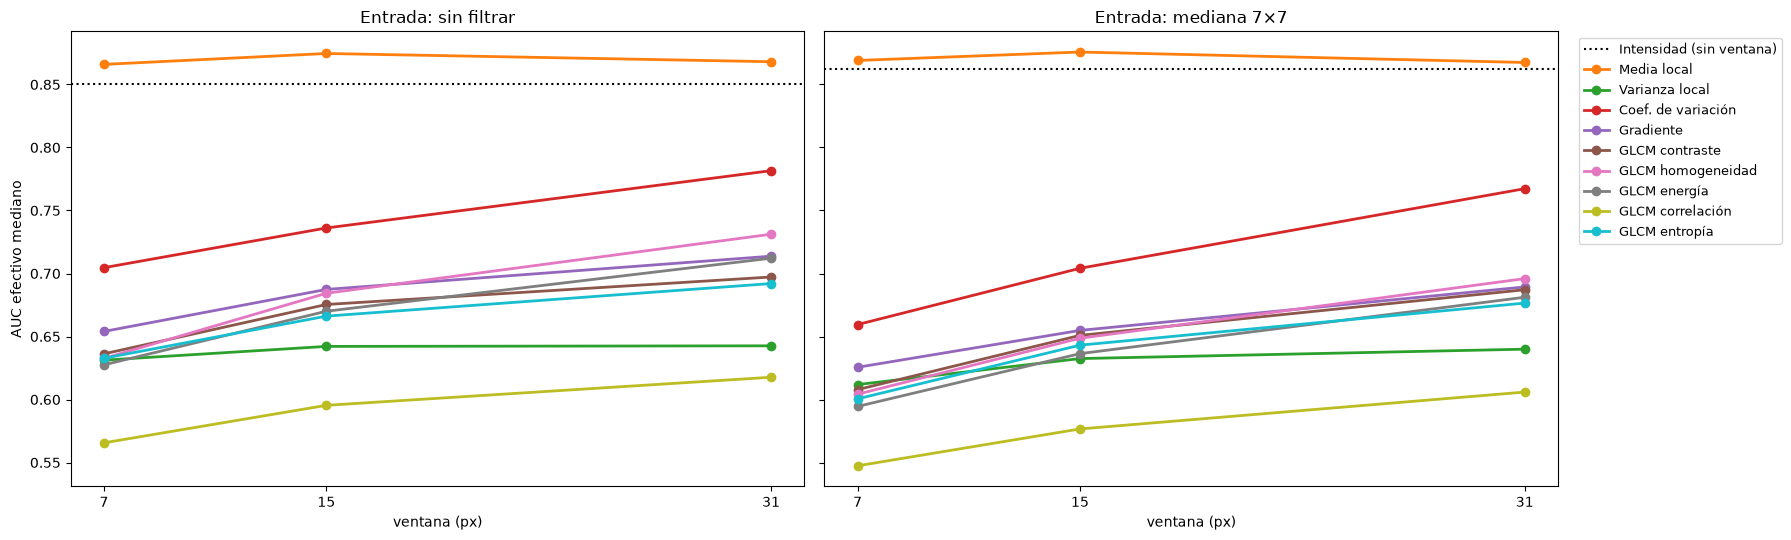

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), sharey=True)
colores = plt.cm.tab10(np.linspace(0, 1, 10))
for ax, e in zip(axes, ENTRADAS):
    for color, nombre in zip(colores, mapas.MAPAS):
        if nombre == "intensidad":
            valor = resumen.query("mapa == 'intensidad' and entrada == @e")["auc_efectivo"].iloc[0]
            ax.axhline(valor, color="black", linestyle=":", label="Intensidad (sin ventana)")
            continue
        datos = resumen.query("mapa == @nombre and entrada == @e")
        ax.plot(datos["ventana"], datos["auc_efectivo"], "o-", color=color, label=NOMBRES[nombre], linewidth=2)
    ax.set_xticks(mapas.VENTANAS)
    ax.set_xlabel("ventana (px)")
    ax.set_title(f"Entrada: {ENTRADAS[e]}")
axes[0].set_ylabel("AUC efectivo mediano")
axes[1].legend(fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Qué vemos:**
- Para la **media local** la ventana casi no importa (0,87–0,88; la mejor es 15).
- Para **todos los mapas de textura** la separabilidad **crece con la ventana** y la mejor es la de 31 px: con más píxeles, la estimación de la textura es más estable. Por ejemplo, el coeficiente de variación pasa de 0,70 (7 px) a 0,78 (31 px).
- Podría seguir mejorando con ventanas todavía más grandes, pero hay un costo que esta medida casi no ve: en la sección 2.1 vimos que con 31 px el mapa **ya no sigue el borde**. Nuestra medida compara el interior de la lesión con un anillo que empieza 5 px afuera, así que no penaliza un borde borroso. Además, muchas lesiones son chicas (en la Parte 0, la mediana de las benignas ocupa el 4 % de la imagen), y una ventana más grande que la lesión mezcla lesión y tejido en todos lados. No probamos ventanas más grandes que 31 px; la Parte 5 tiene que verificar con Dice si los mapas de 31 px dan un **contorno** preciso.

### 5.3 ¿Sin filtrar o con la mediana? Verificación de la Parte 3

Para cada mapa, con su mejor ventana, comparamos el AUC efectivo de las dos entradas **imagen por imagen** con la prueba de Wilcoxon (pareada).

In [12]:
filas = []
for nombre in mapas.MAPAS:
    datos = resumen[resumen["mapa"] == nombre]
    v = int(datos.loc[datos["auc_efectivo"].idxmax(), "ventana"])          # mejor ventana del mapa
    par = sep[(sep["mapa"] == nombre) & (sep["ventana"] == v)].pivot(index="id", columns="entrada", values="auc_efectivo")
    p = wilcoxon(par["sin_filtrar"], par["mediana_7x7"]).pvalue
    filas.append({"mapa": NOMBRES[nombre], "ventana": v,
                  "AUC sin filtrar": par["sin_filtrar"].median(), "AUC mediana 7×7": par["mediana_7x7"].median(),
                  "% imágenes mejor sin filtrar": 100 * (par["sin_filtrar"] > par["mediana_7x7"]).mean(),
                  "p (Wilcoxon)": f"{p:.1e}"})
pd.DataFrame(filas).set_index("mapa").round(3)

,ventana,AUC sin filtrar,AUC mediana 7×7,% imágenes mejor sin filtrar,p (Wilcoxon)
mapa,,,,,
Intensidad,0,0.851,0.862,2.782,2.9e-104
Media local,15,0.875,0.876,31.376,1.2e-22
Varianza local,31,0.643,0.640,61.669,1.4e-08
Coef. de variación,31,0.782,0.767,71.716,5.5e-37
Gradiente,31,0.714,0.689,69.088,3.3e-22
GLCM contraste,31,0.697,0.687,65.688,8.1e-12
GLCM homogeneidad,31,0.731,0.696,70.015,3.4e-27
GLCM energía,31,0.712,0.681,75.270,1.4e-37
GLCM correlación,31,0.618,0.606,61.515,4.3e-10


**Qué vemos:** todas las diferencias son significativas (Wilcoxon pareado, p < 0,001), y van en el sentido que anticipaba la Parte 3:
- **Todos los mapas de textura** (varianza, coeficiente de variación, gradiente y los cinco de la GLCM) separan mejor **sin filtrar**, en el 61–75 % de las imágenes. Filtrar con la mediana borra parte de la diferencia de textura entre lesión y tejido.
- La **intensidad** separa mejor **con la mediana** en el 97 % de las imágenes (0,862 contra 0,851).
- En la **media local** la mediana gana en el 69 % de las imágenes, pero la diferencia es mínima (0,876 contra 0,875): la media local ya promedia el *speckle*, así que filtrar antes agrega poco.
- El **gradiente** separa mejor sin filtrar, aunque la Parte 3 lo había puesto del lado de los "bordes". No es una contradicción: este mapa es el gradiente **promediado en una ventana**, que mide cuántos bordes chicos hay alrededor (o sea, textura), no dónde está el borde de la lesión.

**La recomendación de la Parte 3 queda confirmada:** textura sin filtrar, brillo con la mediana 7 × 7.

### 5.4 Benignas y malignas

¿Los mapas separan igual de bien la lesión del tejido en las dos clases? Para la mejor combinación de cada mapa, AUC efectivo mediano por clase y prueba U de Mann-Whitney (imágenes independientes).

In [13]:
filas = []
for nombre in mapas.MAPAS:
    fila_mejor = resumen.loc[resumen[resumen["mapa"] == nombre]["auc_efectivo"].idxmax()]
    datos = sep[(sep["mapa"] == nombre) & (sep["entrada"] == fila_mejor["entrada"]) & (sep["ventana"] == fila_mejor["ventana"])]
    b = datos.loc[datos["clase"] == "benign", "auc_efectivo"]
    m = datos.loc[datos["clase"] == "malignant", "auc_efectivo"]
    filas.append({"mapa": NOMBRES[nombre], "benignas": b.median(), "malignas": m.median(),
                  "p (Mann-Whitney)": f"{mannwhitneyu(b, m).pvalue:.1e}"})
pd.DataFrame(filas).set_index("mapa").sort_values("benignas", ascending=False).round(3)

,benignas,malignas,p (Mann-Whitney)
mapa,,,
Media local,0.922,0.797,1.8e-25
Intensidad,0.913,0.794,7.4e-24
Coef. de variación,0.808,0.751,1.0e-05
GLCM homogeneidad,0.748,0.712,4.9e-05
GLCM energía,0.737,0.661,4.4e-13
Gradiente,0.735,0.694,6.3e-04
GLCM entropía,0.719,0.657,1.4e-08
GLCM contraste,0.693,0.701,3.6e-01
Varianza local,0.663,0.621,6.9e-06


**Qué vemos:**
- **Todos los mapas separan peor en las malignas** (p < 0,001), salvo el GLCM contraste, que separa igual en las dos clases (0,69 y 0,70, p = 0,36). La media local pasa de 0,92 en las benignas a **0,80** en las malignas. Es lo que vimos en la Parte 0 (menor contraste lesión–tejido) y en la Parte 3 (borde difuso): **las malignas van a ser más difíciles de segmentar**.
- En las malignas la diferencia entre el brillo y la textura **se achica**: la media local cae 0,13, mientras que el coeficiente de variación cae solo 0,06 (de 0,81 a 0,75) y el contraste no cae. Cuando el brillo distingue poco, la textura pesa relativamente más.

### 5.5 ¿Los mapas aportan información distinta? Redundancia

Para la segmentación con *k-means* (Parte 5) conviene combinar mapas que separen bien **y** que no digan lo mismo: dos mapas casi idénticos no suman información. Medimos la **correlación de Spearman** entre los mapas, píxel a píxel, en la lesión y el tejido de 100 imágenes al azar (cada mapa con su mejor entrada y ventana), y tomamos la mediana. Spearman mide si dos mapas **ordenan** los píxeles igual (1 o −1 = el mismo orden; 0 = sin relación), sin importar la escala.

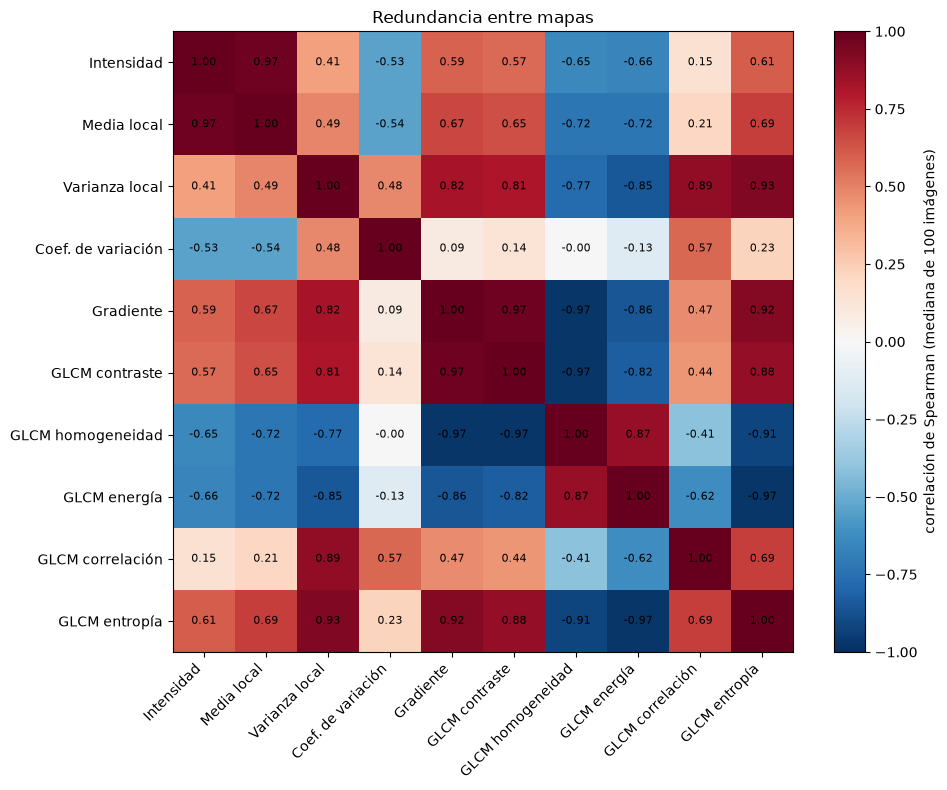

In [14]:
config = {r["mapa"]: (r["entrada"], int(r["ventana"])) for _, r in resumen.loc[idx_mejor].iterrows()}
muestra = con_lesion.sample(100, random_state=SEED)
matrices = []
for id_caso, caso in muestra.iterrows():
    im, masc, mk = cargar_limpio(caso)
    z = dominios.recorte(masc, margen=40)
    region = (masc[z] & ~dominios.contorno(masc[z]) | dominios.anillo(masc[z])) & ~mk[z]
    ent = {e: x[z] for e, x in mapas.entradas(im).items()}
    cache = {}
    columnas = []
    for nombre in mapas.MAPAS:
        e, v = config[nombre]
        v = v if v > 0 else mapas.VENTANAS[0]
        if (e, v) not in cache:
            cache[(e, v)] = mapas.calcular_mapas(ent[e], v)
        columnas.append(cache[(e, v)][nombre][region])
    matrices.append(spearmanr(np.column_stack(columnas)).statistic)
correlacion = pd.DataFrame(np.nanmedian(matrices, axis=0), index=[NOMBRES[m] for m in mapas.MAPAS],
                           columns=[NOMBRES[m] for m in mapas.MAPAS])

fig, ax = plt.subplots(figsize=(10, 8))
h = ax.imshow(correlacion.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(correlacion.columns, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(correlacion.index)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{correlacion.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(h, ax=ax, label="correlación de Spearman (mediana de 100 imágenes)")
ax.set_title("Redundancia entre mapas")
plt.tight_layout()
plt.show()

**Qué vemos:**
- **Intensidad y media local** están casi perfectamente correlacionadas (0,97): dicen lo mismo.
- **Varianza, gradiente, contraste y entropía** forman un bloque muy correlacionado entre sí (0,81–0,97), y la **homogeneidad y la energía** son su opuesto (−0,77 a −0,97). Los seis miden, en el fondo, lo mismo: **cuánta variación local hay**.
- La **media local** también se correlaciona con ese bloque (|ρ| entre 0,49 y 0,72): las zonas oscuras tienen menos variación (Parte 2).
- El **coeficiente de variación** es el más independiente: casi no se correlaciona con el gradiente ni con la GLCM (|ρ| ≤ 0,14) y se correlaciona −0,54 con la media local.

En resumen, los diez mapas cubren **unas tres dimensiones de información**: el **brillo**, la **cantidad de variación local** y la **variación relativa al brillo** (coeficiente de variación).

### 5.6 Selección de mapas para la Parte 5

Recorremos los mapas de mayor a menor AUC efectivo (cada uno con su mejor entrada y ventana) y nos quedamos con uno si cumple tres condiciones:
1. **separa bien:** AUC efectivo mediano ≥ 0,70;
2. **separa siempre en el mismo sentido:** la lesión es menor (o mayor) que el tejido en al menos el 75 % de las imágenes. Un mapa en el que la lesión a veces es más alta y a veces más baja no sirve para segmentar con una regla fija (por ejemplo, "crecer hacia los píxeles de valor bajo");
3. **no es redundante:** no está muy correlacionado ($|\rho| \geq 0{,}7$) con ninguno de los ya elegidos.

In [15]:
orden = resumen.loc[idx_mejor].sort_values("auc_efectivo", ascending=False)
elegidos = []
for _, r in orden.iterrows():
    nombre = NOMBRES[r["mapa"]]
    sentido = max(r["lesion_menor"], 100 - r["lesion_menor"])          # % de imágenes con el sentido mayoritario
    redundante = [e for e in elegidos if abs(correlacion.loc[nombre, NOMBRES[e]]) >= 0.7]
    if r["auc_efectivo"] < 0.70:
        estado = "descartado (AUC < 0,70)"
    elif sentido < 75:
        estado = f"descartado (mismo sentido solo en el {sentido:.0f} % de las imágenes)"
    elif redundante:
        estado = f"descartado (correlación ≥ 0,7 con {', '.join(NOMBRES[e] for e in redundante)})"
    else:
        estado = "ELEGIDO"
        elegidos.append(r["mapa"])
    print(f"{nombre:20s} AUC {r['auc_efectivo']:.3f}, mismo sentido {sentido:3.0f} %  "
          f"({ENTRADAS[r['entrada']]}, ventana {int(r['ventana'])})  ->  {estado}")

Media local          AUC 0.876, mismo sentido  97 %  (mediana 7×7, ventana 15)  ->  ELEGIDO
Intensidad           AUC 0.862, mismo sentido  97 %  (mediana 7×7, ventana 0)  ->  descartado (correlación ≥ 0,7 con Media local)
Coef. de variación   AUC 0.782, mismo sentido  91 %  (sin filtrar, ventana 31)  ->  ELEGIDO
GLCM homogeneidad    AUC 0.731, mismo sentido  89 %  (sin filtrar, ventana 31)  ->  descartado (correlación ≥ 0,7 con Media local)
Gradiente            AUC 0.714, mismo sentido  86 %  (sin filtrar, ventana 31)  ->  ELEGIDO
GLCM energía         AUC 0.712, mismo sentido  85 %  (sin filtrar, ventana 31)  ->  descartado (correlación ≥ 0,7 con Media local, Gradiente)
GLCM contraste       AUC 0.697, mismo sentido  83 %  (sin filtrar, ventana 31)  ->  descartado (AUC < 0,70)
GLCM entropía        AUC 0.692, mismo sentido  82 %  (sin filtrar, ventana 31)  ->  descartado (AUC < 0,70)
Varianza local       AUC 0.643, mismo sentido  66 %  (sin filtrar, ventana 31)  ->  descartado (AUC < 0,7

**Qué vemos:** quedan **tres mapas**, uno por cada dimensión de la sección 5.5:
1. **Media local** sobre la mediana 7 × 7, ventana 15 px (brillo);
2. **Coeficiente de variación** sin filtrar, ventana 31 px (variación relativa);
3. **Gradiente** sin filtrar, ventana 31 px (cantidad de variación).

La **intensidad** queda afuera por redundante con la media local, y la **homogeneidad y la energía** por redundantes con la media o el gradiente. El **contraste y la entropía** quedan apenas por debajo de AUC 0,70 (0,697 y 0,692), y de todos modos serían redundantes con el gradiente (ρ = 0,97 y 0,92). La **varianza** y la **correlación** separan poco y sin un sentido consistente (66 % y 55 %).

El umbral de redundancia (0,7) es una decisión nuestra: la homogeneidad (|ρ| = 0,72 con la media) quedó justo por encima y el gradiente (0,67) justo por debajo. Representan la misma familia ("cuánta variación hay"), así que da casi lo mismo usar uno u otro.

## 6. Conclusiones

Calculamos 10 mapas de características con 3 ventanas sobre 2 entradas en las 647 ecografías con lesión, y medimos, con las máscaras del radiólogo, cuánto separa cada uno la lesión del tejido que la rodea.

| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿Qué separa mejor la lesión del tejido? | El **brillo**: media local (AUC 0,88) e intensidad (0,86). La lesión es más oscura en el 97 % de las imágenes | Sección 5.1 |
| ¿Algún mapa de textura supera a la imagen original? | **No.** El mejor es el coeficiente de variación (0,78); los de la GLCM, 0,62–0,73. La hipótesis del anteproyecto se cumple solo en parte | Sección 5.1 |
| ¿Qué tamaño de ventana? | Brillo: da igual (15 px). Textura: la más grande probada (31 px), aunque con un borde más borroso | Secciones 2.1 y 5.2 |
| ¿Filtrar antes? | Textura **sin filtrar**; brillo con la **mediana 7 × 7**. Confirma la Parte 3 | Sección 5.3, Wilcoxon p < 0,001 |
| ¿Benignas y malignas? | Todos los mapas separan **peor en las malignas** (media local: 0,92 contra 0,80); en ellas la textura pesa relativamente más | Sección 5.4 |
| ¿Cuánta información distinta aportan? | Unas **tres dimensiones**: brillo, cantidad de variación y variación relativa | Sección 5.5 |
| ¿Qué mapas usar? | **Media local** (mediana 7 × 7, 15 px), **coeficiente de variación** (sin filtrar, 31 px) y **gradiente** (sin filtrar, 31 px) | Sección 5.6 |

**Para la Parte 5 (segmentación):**
- **Crecimiento de regiones** desde una semilla: sobre la **media local**, que separa mejor y tiene un sentido muy consistente (lesión más oscura).
- **k-means:** sobre el vector **(media local, coeficiente de variación, gradiente)**, estandarizado (cada mapa tiene su escala). Es la forma de comprobar si la textura **suma** algo al brillo, que acá no pudimos medir porque cada AUC mira un mapa por vez.
- **Chan-Vese:** sobre la media local (separa la imagen en dos regiones de distinta media, justo lo que este mapa distingue mejor).
- Esperar **peores resultados en las malignas**, y verificar con **Dice** que las ventanas de 31 px no deformen el contorno.

**Limitaciones:**
1. La separabilidad compara el **interior** de la lesión con un **anillo** de tejido; no mide qué tan bien un mapa ubica el **borde**. Favorece las ventanas grandes, que lo borronean.
2. Los píxeles vecinos no son independientes (el *speckle* forma granos), así que el AUC de cada imagen es una medida descriptiva, no un test. Por eso los tests se hacen entre imágenes.
3. La GLCM usa 16 niveles con la cuantización de cada recorte (mínimo y máximo de esa zona), así que los valores absolutos no son comparables entre imágenes; la separabilidad sí, porque se mide dentro de cada una.
4. No probamos ventanas mayores a 31 px ni otras distancias de la GLCM.
5. La redundancia se estimó en 100 imágenes al azar, no en las 647.